In [1]:
import pandas as pd

In [ ]:
class BackTestCrossMA:

    def __init__(self) -> None:
        self.df = pd.DataFrame()
        self.days = []
        self.trades = []

    def load_data(self, path:str) -> None:
        self.df = pd.read_csv(path)
        self.df['date'] = pd.to_datetime(self.df['date'], unit='ms')
        self.df.set_index(self.df['date'], inplace=True)
        del self.df['date']

    def populate_indicators(self):
        self.df['ma100'] = self.df['close'].rolling(100).mean()
        self.df['ma200'] = self.df['close'].rolling(200).mean()

    def populate_signals(self):
        self.df['buy_signal'] = False
        self.df['sell_signal'] = False
        self.df.loc[self.df['ma100'] > self.df['ma200'], 'buy_signal'] = True
        self.df.loc[self.df['ma100'] < self.df['ma200'], 'sell_signal'] = True

    def run_back_test(self):
        balance = 1000
        position = None
        asset = 'BTC'
        fee = 0.001
    
        self.days = []
        self.trades = []
        previous_day = -1


        for index, row in self.df.iterrows():

            current_day = index.day
            if previous_day != current_day:
                temp_balance = balance

                if position:

                    close_price = row['close']

                    trade_result = (close_price - position['open_price']) / position['open_price']
                    close_size = position['open_size'] +  position['open_size']  * trade_result

                    fees = fee * close_size
                    close_size -= fees
                    temp_balance += close_size - position['open_size']

                self.days.append(
                    {
                        "day":index.date(),
                        "balance": temp_balance,
                        "price": row['close']
                    }
                )

            previous_day = current_day
            
            if position is None and row['buy_signal']:
                open_price = row['close']
            
                open_size = balance
                fees = fee * open_size
                open_size -= fees
                balance -= fees
                stop_loss = open_price - 0.15 * open_price

                position = {
                    "open_price": open_price,
                    "open_size": balance,
                    "open_date": index,
                    "open_fee": fees,
                    "open_reason": "Market Buy",
                    "open_balance": balance,
                    "stop_loss": stop_loss
                }

                # print(f'{index} Buy for {balance} of {asset} {open_size} at {open_price} fees {fees}$')
            if position and row['low'] <= position['stop_loss']:
                            close_price = position['stop_loss']
                            trade_result = (close_price - position['open_price']) / position['open_price']
            
                            close_size = position['open_size'] +  position['open_size']  * trade_result
                            fees = fee * close_size
                            close_size -= fees
            
                            balance += close_size - position['open_size']
            
                            self.trades.append(
                                {
                                    "open_date": position["open_date"],
                                    "close_date": index,
                                    "open_price": position["open_price"],
                                    "close_price": close_price,
                                    "open_size": position["open_size"],
                                    "close_size": close_size,
                                    "open_fee": position["open_fee"],
                                    "close_fee": fees,
                                    "open_reason": position["open_reason"],
                                    "close_reason": "Stop Loss",
                                    "open_balance": position["open_balance"],
                                    "close_balance": balance,
                                }
                            )
            
                            
                            position = None
                            # print(f'{index} Sell for {balance} of {asset} at {close_price} fees {fees}')
            
            
            if position and row['sell_signal']:
                close_price = row['close']
                trade_result = (close_price - position['open_price']) / position['open_price']

                close_size = position['open_size'] +  position['open_size']  * trade_result
                fees = fee * close_size
                close_size -= fees

                balance += close_size - position['open_size']

                self.trades.append(
                    {
                        "open_date": position["open_date"],
                        "close_date": index,
                        "open_price": position["open_price"],
                        "close_price": close_price,
                        "open_size": position["open_size"],
                        "close_size": close_size,
                        "open_fee": position["open_fee"],
                        "close_fee": fees,
                        "open_reason": position["open_reason"],
                        "close_reason": "Market Sell",
                        "open_balance": position["open_balance"],
                        "close_balance": balance,
                    }
                )

                
                position = None
                # print(f'{index} Sell for {balance} of {asset} at {close_price} fees {fees}')


        print(f'Final balance {round(balance,2)} $')

    def backtest_analysis(self):
        df_days = pd.DataFrame(self.days)
        df_trades = pd.DataFrame(self.trades)

        if df_days.empty:
              raise ValueError("No days found")

        if df_trades.empty:
                      raise ValueError("No trades found")


        df_days['evolution'] = df_days['balance'].diff()
        df_days['daily_return'] = df_days['balance'].pct_change()

        df_trades['trade_result'] = df_trades['close_size'] - df_trades['open_size']
        df_trades['trade_result_pct'] = df_trades['trade_result']/df_trades['open_size']
        df_trades['trades_duration'] = df_trades['close_date'] - df_trades['open_date']

        df_days['balance_ath'] = df_days['balance'].cummax()
        df_days['drawdown'] = df_days['balance_ath'] - df_days['balance']
        df_days['drawdown_pct'] = df_days['drawdown'] / df_days['balance_ath']


        total_trades = len(df_trades)
        total_days = len(df_days)

        good_trades = df_trades.loc[df_trades["trade_result"] > 0]
        total_good_trades = len(good_trades)
        avg_profit_good_trades = good_trades["trade_result_pct"].mean()
        mean_good_trades_duration = good_trades["trades_duration"].mean()
        global_win_rate = total_good_trades / total_trades

        bad_trades = df_trades.loc[df_trades["trade_result"] < 0]
        total_bad_trades = len(bad_trades)
        avg_profit_bad_trades = bad_trades["trade_result_pct"].mean()
        mean_bad_trades_duration = bad_trades["trades_duration"].mean()
        max_days_drawdown = df_days["drawdown_pct"].max()
        initial_balance = df_days.iloc[0]["balance"]
        final_balance = df_days.iloc[-1]["balance"]
        balance_evolution = (final_balance - initial_balance) / initial_balance
        mean_trades_duration = df_trades["trades_duration"].mean()
        avg_profit = df_trades["trade_result_pct"].mean()
        mean_trades_duration = df_trades['trades_duration'].mean()
        mean_trades_per_days = total_trades/total_days

        best_trade = df_trades.loc[df_trades["trade_result_pct"].idxmax()]
        worst_trade = df_trades.loc[df_trades["trade_result_pct"].idxmin()]

        sharpe_ratio = (365**(0.5) * df_days['daily_return'].mean())/df_days['daily_return'].std()
        

        print(f"Period: [{df_days.iloc[0]['day']}] -> [{df_days.iloc[-1]['day']}]")
        print(f"Initial balance: {round(initial_balance,2)} $")
        
        print("\n--- General Information ---")
        print(f"Final balance: {round(final_balance,2)} $")
        print(f"Performance: {round(balance_evolution*100,2)} %")
        print(f"Worst Drawdown: -{round(max_days_drawdown*100, 2)}%")
        print(f"Total trades on the period: {total_trades}")
        print(f"Average Profit: {round(avg_profit*100, 2)} %")
        print(f"Global Win rate: {round(global_win_rate*100, 2)} %")
        
        print("\n--- Trades Information ---")
        print(f"Mean Trades per day: {round(mean_trades_per_days, 2)}")
        print(f"Mean Trades Duration: {mean_trades_duration}")
        print(f"Best trades: +{round(best_trade['trade_result_pct']*100, 2)} % the {best_trade['open_date']} -> {best_trade['close_date']}")
        print(f"Worst trades: {round(worst_trade['trade_result_pct']*100, 2)} % the {worst_trade['open_date']} -> {worst_trade['close_date']}")
        print(f"Total Good trades on the period: {total_good_trades}")
        print(f"Total Bad trades on the period: {total_bad_trades}")
        print(f"Average Good Trades result: {round(avg_profit_good_trades*100, 2)} %")
        print(f"Average Bad Trades result: {round(avg_profit_bad_trades*100, 2)} %")
        print(f"Mean Good Trades Duration: {mean_good_trades_duration}")
        print(f"Mean Bad Trades Duration: {mean_bad_trades_duration}")
        
        print("\n--- Trades reasons ---")
        print(df_trades["open_reason"].value_counts().to_string())
        print(df_trades["close_reason"].value_counts().to_string())

        print(f"Sharpe Ratio: {round(sharpe_ratio,2)}")

        return df_days
    
    def plot_equity_vs_asset(self):
	    df_days = self.df_days.copy()
		df_days = df_days.set_index('day')
	    fig, ax_left = plt.subplots(figsize=(15, 20), nrows=4, ncols=1)
	
	    ax_left[0].title.set_text("Profit and Loss curve")
	    ax_left[0].plot(df_days['balance'], color='royalblue', lw=1)
	    ax_left[0].fill_between(df_days['balance'].index, df_days['balance'], alpha=0.2, color='royalblue')
	    ax_left[0].axhline(y=df_days.iloc[0]['balance'], color='black', alpha=0.3)
	    ax_left[0].legend(['Wallet evolution (equity)'], loc ="upper left")
	
	  ax_left[1].title.set_text("Asset evolution")
	  ax_left[1].plot(df_days['price'], color='sandybrown', lw=1)
	  ax_left[1].fill_between(df_days['price'].index, df_days['price'], alpha=0.2, color='sandybrown')
	  ax_left[1].axhline(y=df_days.iloc[0]['price'], color='black', alpha=0.3)
	  ax_left[1].legend(['Asset evolution'], loc ="upper left")
	
	  ax_left[2].title.set_text("Drawdown curve")
	  ax_left[2].plot(-df_days['drawdown_pct']*100, color='indianred', lw=1)
	  ax_left[2].fill_between(df_days['drawdown_pct'].index, -df_days['drawdown_pct']*100, alpha=0.2, color='indianred')
	  ax_left[2].axhline(y=0, color='black', alpha=0.3)
	  ax_left[2].legend(['Drawdown in %'], loc ="lower left")
	
	  ax_right = ax_left[3].twinx()
	
	  ax_left[3].title.set_text("P&L VS Asset (not on the same scale)")
	  ax_left[3].plot(df_days['balance'], color='royalblue', lw=1)
	  ax_right.plot(df_days['price'], color='sandybrown', lw=1)
	  ax_left[3].legend(['Wallet evolution (equity)'], loc ="lower right")
	  ax_right.legend(['Asset evolution'], loc ="upper left")
	
	  plt.show()
bt = BackTestCrossMA()
bt.load_data('../data/BCH-USDT.csv')
bt.populate_indicators()
bt.populate_signals()
bt.run_back_test()
bt.backtest_analysis()

Final balance 1367.94 $
Period: [2019-11-28] -> [2023-07-03]
Initial balance: 1000.0 $

--- General Information ---
Final balance: 3762.85 $
Performance: 276.29 %
Worst Drawdown: -72.84%
Total trades on the period: 96
Average Profit: 1.31 %
Global Win rate: 35.42 %

--- Trades Information ---
Mean Trades per day: 0.07
Mean Trades Duration: 6 days 09:51:52.500000
Best trades: +69.18 % the 2019-12-27 22:00:00 -> 2020-01-23 02:00:00
Worst trades: -15.09 % the 2022-11-04 06:00:00 -> 2022-11-08 19:00:00
Total Good trades on the period: 34
Total Bad trades on the period: 62
Average Good Trades result: 13.53 %
Average Bad Trades result: -5.39 %
Mean Good Trades Duration: 10 days 14:38:49.411764705
Mean Bad Trades Duration: 4 days 02:35:48.387096774

--- Trades reasons ---
open_reason
Market Buy    96
close_reason
Market Sell    87
Stop Loss       9
Sharpe Ratio: 0.84


,day,balance,price,evolution,daily_return,balance_ath,drawdown,drawdown_pct
0,2019-11-28,1000.000000,218.98,NaN,NaN,1000.000000,0.000000,0.000000
1,2019-11-29,1000.000000,218.48,0.000000,0.000000,1000.000000,0.000000,0.000000
2,2019-11-30,1000.000000,224.12,0.000000,0.000000,1000.000000,0.000000,0.000000
3,2019-12-01,1000.000000,215.49,0.000000,0.000000,1000.000000,0.000000,0.000000
4,2019-12-02,1000.000000,214.55,0.000000,0.000000,1000.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...
1309,2023-06-29,2882.427316,225.90,-28.071448,-0.009645,3503.231491,620.804175,0.177209
1310,2023-06-30,3363.469856,263.60,481.042540,0.166888,3503.231491,139.761635,0.039895
1311,2023-07-01,3878.963719,304.00,515.493863,0.153263,3878.963719,0.000000,0.000000
1312,2023-07-02,3631.424587,284.60,-247.539132,-0.063816,3878.963719,247.539132,0.063816


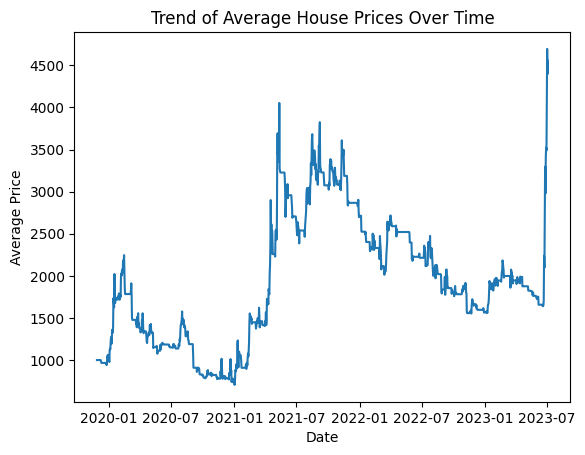

In [21]:
import matplotlib.pyplot as plt

df_days = pd.DataFrame(bt.days)

plt.plot(df_days['day'], df_days['balance'])
plt.xlabel('Date')
plt.ylabel('Average Price')
plt.title('Trend of Average House Prices Over Time')
plt.show()

,day,balance,price
0,2019-11-28,1000.000000,218.98
1,2019-11-29,1000.000000,218.48
2,2019-11-30,1000.000000,224.12
3,2019-12-01,1000.000000,215.49
4,2019-12-02,1000.000000,214.55
...,...,...,...
1309,2023-06-29,3813.299001,225.90
1310,2023-06-30,4449.692858,263.60
1311,2023-07-01,5131.663994,304.00
1312,2023-07-02,4804.182805,284.60


In [14]:
pd.DataFrame(bt.trades)

,open_date,close_date,open_price,close_price,open_size,close_size,open_fee,close_fee,open_reason,close_reason,open_balance,close_balance
0,2019-12-09 08:00:00,2019-12-10 15:00:00,212.11,205.35,999.000000,966.194453,1.000000,0.967162,Market Buy,Market Sell,999.000000,966.194453
1,2019-12-24 07:00:00,2019-12-27 18:00:00,189.76,200.15,965.228258,1017.059683,0.966194,1.018078,Market Buy,Market Sell,965.228258,1017.059683
2,2019-12-27 22:00:00,2020-01-23 02:00:00,201.85,341.83,1016.042623,1718.932554,1.017060,1.720653,Market Buy,Market Sell,1016.042623,1718.932554
3,2020-01-28 14:00:00,2020-02-17 08:00:00,374.66,389.56,1717.213622,1783.720655,1.718933,1.785506,Market Buy,Market Sell,1717.213622,1783.720655
4,2020-03-05 00:00:00,2020-03-09 13:00:00,325.35,270.00,1781.936935,1477.307052,1.783721,1.478786,Market Buy,Market Sell,1781.936935,1477.307052
...,...,...,...,...,...,...,...,...,...,...,...,...
83,2023-05-05 22:00:00,2023-05-06 23:00:00,120.10,117.00,1874.528953,1824.317798,1.876405,1.826144,Market Buy,Market Sell,1874.528953,1824.317798
84,2023-05-13 08:00:00,2023-05-13 10:00:00,114.10,114.00,1822.493481,1819.075307,1.824318,1.820896,Market Buy,Market Sell,1822.493481,1819.075307
85,2023-05-17 18:00:00,2023-05-21 21:00:00,117.90,114.50,1817.256232,1763.085349,1.819075,1.764850,Market Buy,Market Sell,1817.256232,1763.085349
86,2023-05-29 20:00:00,2023-06-02 21:00:00,115.20,114.70,1761.322264,1751.923958,1.763085,1.753678,Market Buy,Market Sell,1761.322264,1751.923958
